%pip install awscli
%pip install boto3

import os
import sys

!git clone https://${github_astro_guard_token}@github.com/zLPrime/astro-guard.git

In [1]:
import os
import sys

sys.path.append('./astro-guard/ml-workbench')

# Эксперимент 2.2: ширина 400, 10000 объектов на класс (тестовая выборка из доверенного источника)

In [2]:
from astro_data import dataloader
from sklearn.preprocessing import LabelEncoder
import random

random.seed(42)
label_encoder = LabelEncoder()
best_model_path='models/experiment2.2.pth'
log_file = 'experiment2.2.log'
batch_size = 64

dataset = dataloader.get_jd_magn_1d_dataset(
    os.environ['aws_access_key_id'],
    os.environ['aws_secret_access_key'], label_encoder,
    cache_path='./astro-guard/ml-workbench/astro_data/objects_cache.json',
    items_per_label=10000)

Loading object keys from cache...


In [3]:
import pandas as pd
import numpy as np
import torch
import torchvision.transforms as transforms

def _get_jd_magn_1d(df: pd.DataFrame, width: int = 400):
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.dropna(how='any', inplace=True)
    x_vals = df['mjd'].to_numpy()
    y_vals = df['mag'].to_numpy()

    if len(x_vals) < 2:
        raise ValueError("Need at least two data points.")

    # Normalize x to [0, 1] and interpolate y over fixed-width samples
    x_norm = (x_vals - x_vals.min()) / (x_vals.max() - x_vals.min())
    y_interp = np.interp(np.linspace(0, 1, width), x_norm, y_vals)

    if (np.isnan(y_interp).any() or np.isinf(y_interp).any() or
        np.isclose(y_interp.max(), y_interp.min())):
        raise ValueError("Bad data: NaNs, Infs, or flat signal")
    
    y_norm = (y_interp - y_interp.min()) / (y_interp.max() - y_interp.min())

    return torch.tensor(y_norm, dtype=torch.float32).unsqueeze(0)

transform = transforms.Compose([
    transforms.Lambda(_get_jd_magn_1d)
])

ztf_dataset = dataloader.AstroFileDataset('ztf_lightcurves', transform, label_encoder, 10000)

In [4]:
from torch.utils.data import random_split, Subset

target_class = label_encoder.transform(['nonvariables'])[0]

# Get indices for each subset
nonvariables_indices = dataset.get_class_indices('nonvariables')
variables_indices = dataset.get_class_indices('variables')

# Create subsets
nonvariables_subset = Subset(dataset, nonvariables_indices)
variables_subset = Subset(dataset, variables_indices)

dataset_size = len(variables_subset)
smaller_size = 1000 # тот же размер, что в первом эксперименте
larger_size = dataset_size - smaller_size

smaller_variables_dataset, larger_variables_dataset = random_split(variables_subset, [smaller_size, larger_size])

smaller_dataset = torch.utils.data.ConcatDataset([nonvariables_subset, smaller_variables_dataset])

train_dataloader, test_dataloader = dataloader.get_train_test(smaller_dataset, batch_size=batch_size)
train_dataset = torch.utils.data.ConcatDataset([train_dataloader.dataset, larger_variables_dataset, ztf_dataset])
train_dataloader, _ = dataloader.get_train_test(train_dataset, split_ratio=1.0, batch_size=batch_size)

In [5]:
larger_size

9000

In [6]:
len(test_dataloader.dataset)

602

In [7]:
from astro_model.model import JDLightCurve1DCNN
from astro_train.trainer import train_and_monitor
from torch import cuda

model = JDLightCurve1DCNN(2)
device = 'cuda' if cuda.is_available() else 'cpu'

In [8]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    train_and_monitor(model, train_dataloader, 100, device=device, val_loader=test_dataloader, best_model_path=best_model_path, patience=10, log_file=log_file)

Epoch 1/100: 100%|██████████| 296/296 [00:51<00:00,  5.71it/s, Train Loss=0.2745, Train Acc=88.42%]


Validation Loss: 0.7021 | Validation Accuracy: 66.61%
Best model saved with accuracy: 66.61%


Epoch 2/100: 100%|██████████| 296/296 [00:50<00:00,  5.85it/s, Train Loss=0.1415, Train Acc=94.65%]


Validation Loss: 0.8064 | Validation Accuracy: 66.61%


Epoch 3/100: 100%|██████████| 296/296 [00:50<00:00,  5.88it/s, Train Loss=0.1261, Train Acc=95.37%]


Validation Loss: 0.7821 | Validation Accuracy: 67.61%
Best model saved with accuracy: 67.61%


... (48 outputs left out)

Epoch 28/100: 100%|██████████| 296/296 [00:55<00:00,  5.34it/s, Train Loss=0.0192, Train Acc=99.42%]


Validation Loss: 1.4042 | Validation Accuracy: 72.26%


Epoch 29/100: 100%|██████████| 296/296 [00:52<00:00,  5.69it/s, Train Loss=0.0150, Train Acc=99.52%]


Validation Loss: 1.2342 | Validation Accuracy: 75.58%
Early stopping triggered at epoch 29


In [9]:
from astro_test.test import print_evaluate
import torch

model.load_state_dict(torch.load(best_model_path, weights_only=True))

print_evaluate(model, test_dataloader, label_encoder, device)

/usr/local/lib/python3.10/dist-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()
100%|██████████| 10/10 [00:02<00:00,  4.16it/s]


Accuracy: 0.7591362126245847
Classification Report:
               precision    recall  f1-score   support

nonvariables       0.92      0.56      0.70       298
   variables       0.69      0.95      0.80       304

    accuracy                           0.76       602
   macro avg       0.81      0.76      0.75       602
weighted avg       0.80      0.76      0.75       602



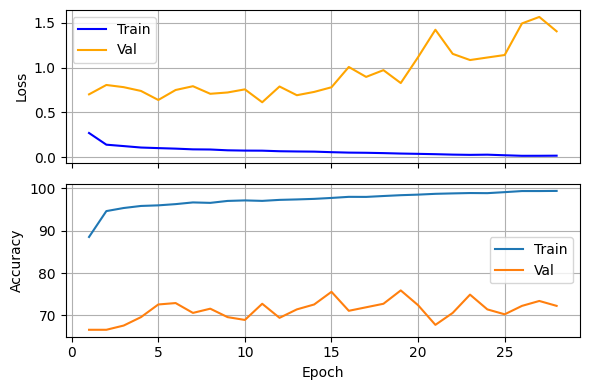

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(log_file)

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(6, 4))

ax1.plot(df['epoch'], df['train_loss'], label='Train', color='blue')
ax1.plot(df['epoch'], df['val_loss'], label='Val', color='orange')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(df['epoch'], df['train_acc'], label='Train')
ax2.plot(df['epoch'], df['val_acc'], label='Val')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()